In [62]:
import pandas as pd
import warnings
warnings.simplefilter(action='ignore',category=FutureWarning)
data = pd.read_csv('heart_disease.csv')

In [63]:
data.isnull().sum()

age          0
sex          0
cp           0
trestbps     0
chol         0
fbs          0
restecg      0
thalch       0
exang        0
oldpeak     62
slope        0
thal         0
num          0
dtype: int64

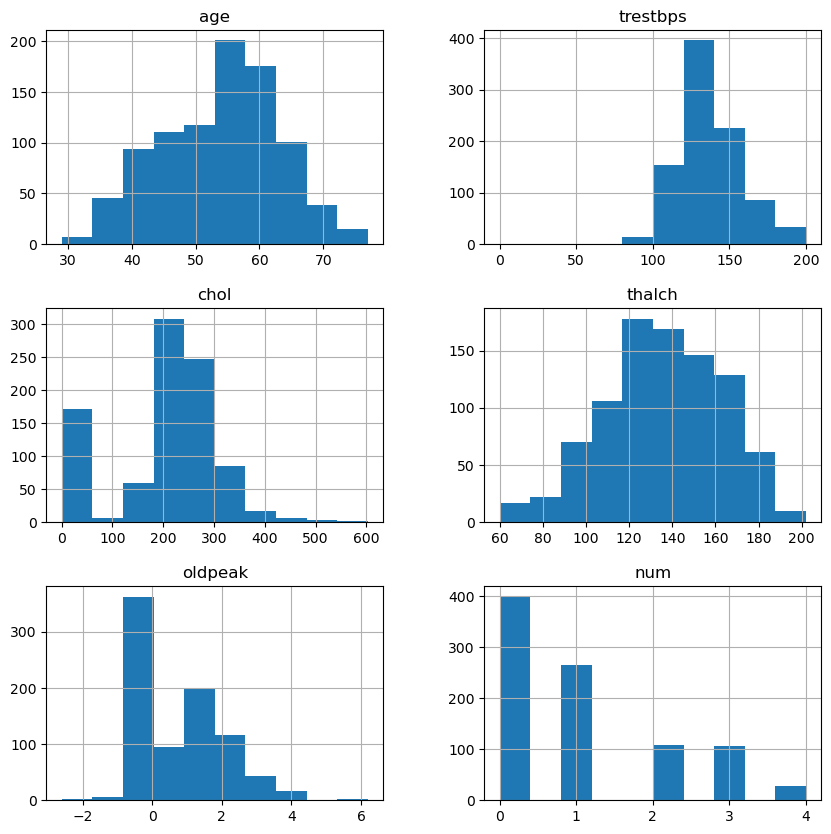

In [64]:
import matplotlib.pyplot as plt
data.hist(figsize=(10,10))
plt.show()

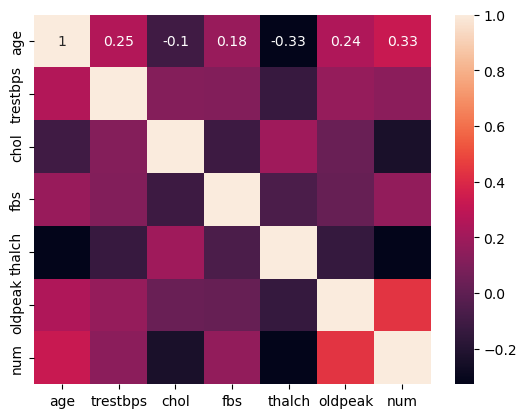

In [65]:
import seaborn as sns
corr_matrix = data.corr()
sns.heatmap(corr_matrix, annot=True)
plt.show()

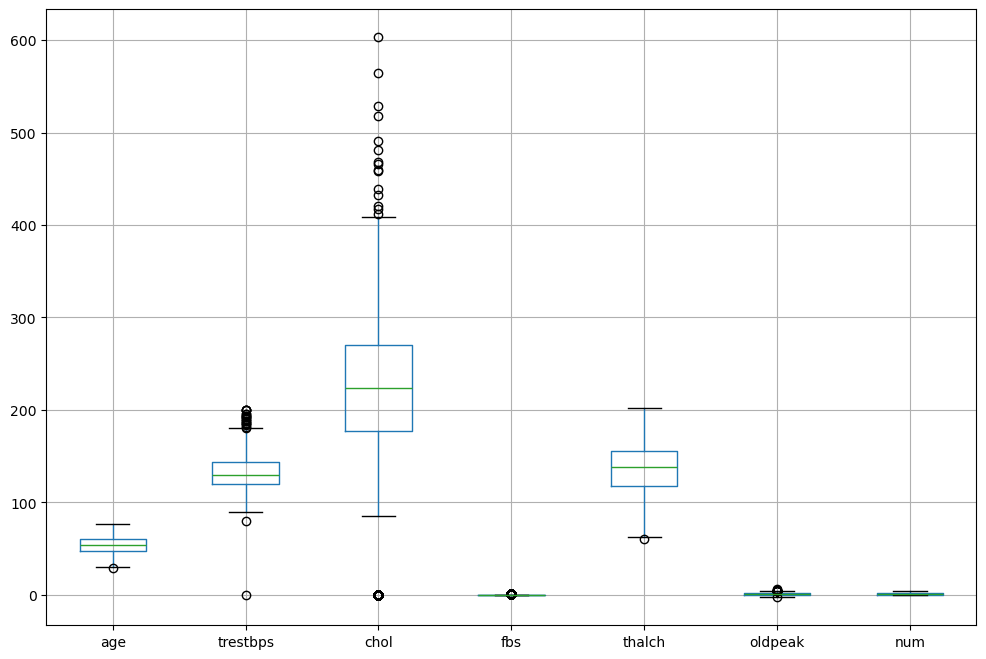

In [66]:
data.boxplot(figsize=(12,8))
plt.show()

In [67]:
from sklearn.preprocessing import LabelEncoder
# List of categorical columns
categorical_cols = ['sex', 'fbs', 'exang']
# Create a LabelEncoder object
labelencoder = LabelEncoder()
# Apply label encoding to each categorical column
for col in categorical_cols:
    data[col] = labelencoder.fit_transform(data[col])

In [68]:
# Apply one-hot encoding to categorical columns with multiple categories
data = pd.get_dummies(data, columns=['cp', 'restecg', 'slope', 'thal'])

In [69]:
from sklearn.preprocessing import StandardScaler
# Select numerical columns
numerical_cols = ['age', 'trestbps', 'chol', 'thalch', 'oldpeak']
scaler = StandardScaler()
# Apply scaling to the numerical columns
data[numerical_cols] = scaler.fit_transform(data[numerical_cols])

In [70]:
from sklearn.preprocessing import MinMaxScaler
# Create a MinMax scaler object
scaler = MinMaxScaler()
# Apply scaling to the numerical columns
data[numerical_cols] = scaler.fit_transform(data[numerical_cols])

In [71]:
from sklearn.model_selection import train_test_split
X = data.drop('num', axis=1)
y = data['num']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [72]:
from sklearn.impute import SimpleImputer

# Create an imputer to fill missing values with the mean
imputer = SimpleImputer(strategy='mean')

# Apply the imputer to the numerical columns
X_train[numerical_cols] = imputer.fit_transform(X_train[numerical_cols])
X_test[numerical_cols] = imputer.transform(X_test[numerical_cols])

In [73]:
# Impute categorical columns with the most frequent value
categorical_cols = ['sex', 'fbs', 'exang', 'cp_asymptomatic', 'cp_atypical angina', 'cp_non-anginal', 'cp_typical angina', 'restecg_lv hypertrophy', 'restecg_normal', 'restecg_st-t abnormality', 'slope_downsloping', 'slope_flat', 'slope_upsloping', 'thal_fixed defect', 'thal_normal', 'thal_reversable defect']
imputer_cat = SimpleImputer(strategy='most_frequent')

# Apply the imputer to the categorical columns
X_train[categorical_cols] = imputer_cat.fit_transform(X_train[categorical_cols])
X_test[categorical_cols] = imputer_cat.transform(X_test[categorical_cols])

In [74]:
X_train = X_train.dropna()
y_train = y_train[X_train.index]
X_test = X_test.dropna()
y_test = y_test[X_test.index]

In [75]:
from sklearn.tree import DecisionTreeClassifier
clf = DecisionTreeClassifier(random_state=42)
clf.fit(X_train, y_train)

DecisionTreeClassifier(random_state=42)

In [76]:
from sklearn.metrics import precision_score, recall_score, f1_score, accuracy_score

y_pred = clf.predict(X_test)

# For multiclass, we use 'macro', 'micro', or 'weighted' as averaging strategies
print('Accuracy:', accuracy_score(y_test, y_pred))
print('Precision (macro):', precision_score(y_test, y_pred, average='macro'))
print('Recall (macro):', recall_score(y_test, y_pred, average='macro'))
print('F1 Score (macro):', f1_score(y_test, y_pred, average='macro'))

Accuracy: 0.532967032967033
Precision (macro): 0.32868548182049323
Recall (macro): 0.3331565823469327
F1 Score (macro): 0.3307732741656431


In [77]:
from sklearn.model_selection import GridSearchCV
param_grid = {'max_depth': [3, 5, 7, None],
              'min_samples_split': [2, 5, 10],
              'criterion': ['gini', 'entropy']}
grid_search = GridSearchCV(clf, param_grid, cv=5, scoring='accuracy')
grid_search.fit(X_train, y_train)
print("Best Parameters:", grid_search.best_params_)
clf_best = grid_search.best_estimator_

Best Parameters: {'criterion': 'gini', 'max_depth': 3, 'min_samples_split': 2}


In [78]:
y_pred_best = clf_best.predict(X_test)
print('Accuracy:', accuracy_score(y_test, y_pred_best))

Accuracy: 0.5714285714285714


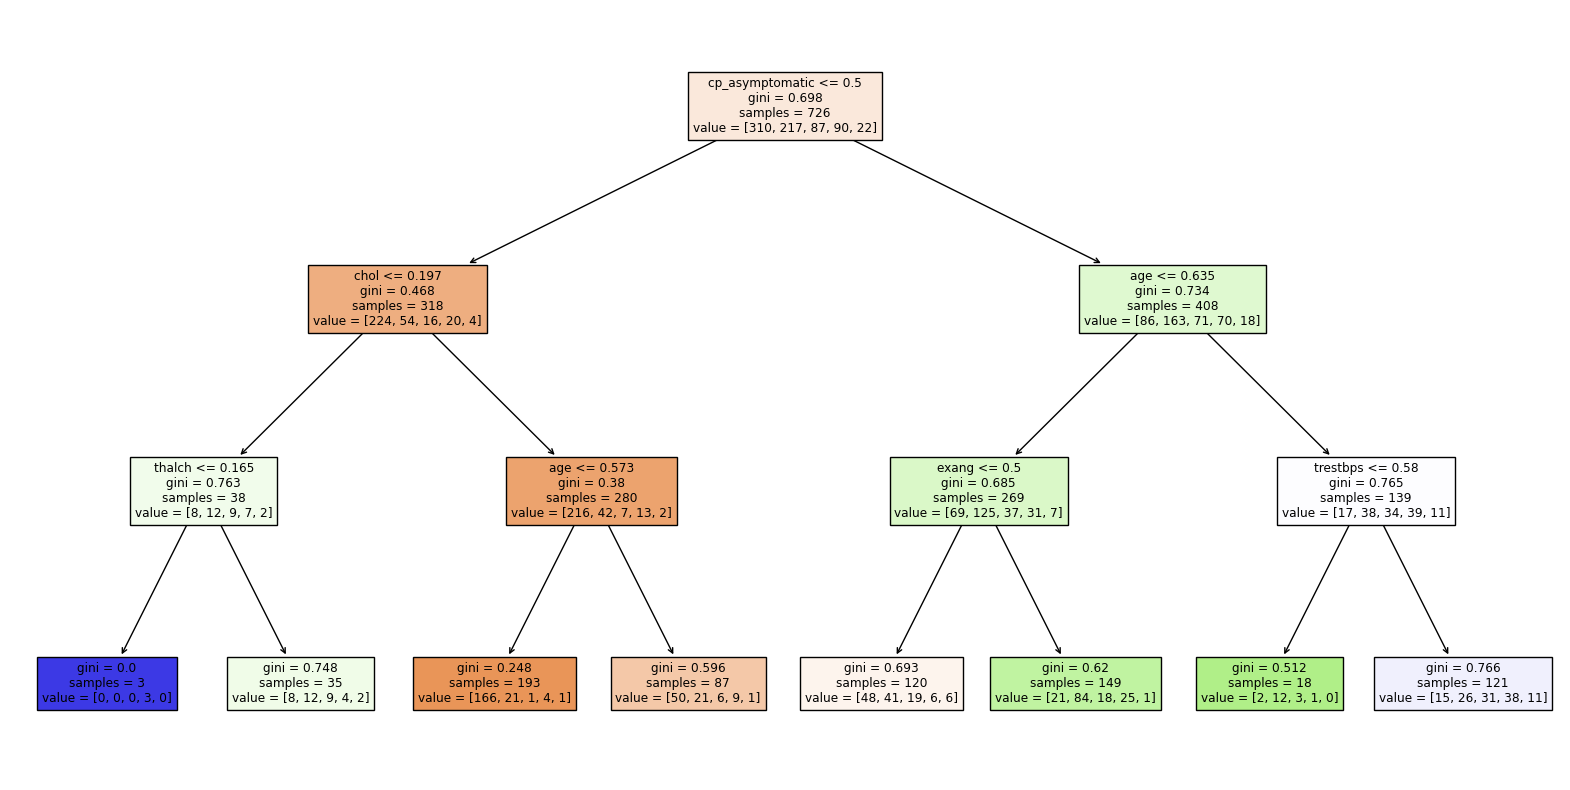

In [79]:
from sklearn import tree
plt.figure(figsize=(20,10))
tree.plot_tree(clf_best, filled=True, feature_names=X.columns)
plt.show()

In [80]:
#Interview Questions:
#What are some common hyperparameters of decision tree models, and how do they affect the model's performance?
#max_depth: Limits the depth of the tree. A shallow tree might underfit, while a deeper tree could overfit.
#min_samples_split: Minimum number of samples required to split a node. Increasing this helps to reduce overfitting.
#criterion: Measures the quality of a split (gini or entropy). Gini is faster, but entropy might provide better results depending on the data.
#min_samples_leaf: The minimum number of samples a leaf node must have. Helps in controlling tree growth.
#max_features: The number of features to consider when looking for the best split. Smaller subsets of features can reduce overfitting.

In [81]:
#What is the difference between the Label encoding and One-hot encoding?
#Label Encoding: Converts categorical labels into integer values (e.g., Red, Green, Blue → 0, 1, 2). It is suitable for ordinal data where the order matters.
#One-Hot Encoding: Converts categorical variables into a binary vector for each category (e.g., Red, Green, Blue → [1, 0, 0], [0, 1, 0], [0, 0, 1]). It is best for nominal data where order does not matter.
#Let me know if you need further clarification or help with code implementation!